# Experiment 5 — Comprehensive Study of CNN Training, Regularization, Optimization,
# Hyperparameter Tuning, Transfer Learning and Cross-Validation

**Course:** CS3807 – Deep Learning Laboratory &nbsp;|&nbsp; **Programme:** B.Tech AI & DS, Semester V &nbsp;|&nbsp; **AY:** 2026–27

**Dataset:** Oxford-IIIT Pet (37-way breed classification, 224x224x3) &nbsp;|&nbsp; **Architecture:** MobileNetV2

| Field | Value |
|---|---|
| Name | _fill in_ |
| Roll Number | _fill in_ |
| Date of Execution | _fill in_ |

This notebook implements Sections 3–13 of the lab manual. Discussion Questions (Section 15)
and the formal report are prepared separately once these results are available, following
the same process as Experiment 4.

## How to Run This Notebook (Google Colab)

1. Upload to Colab, then **Runtime -> Change runtime type -> GPU (T4)**, then Save.
2. Run cells top to bottom. `tensorflow_datasets` and `scikit-learn` are normally
   preinstalled on Colab; uncomment the install cell below if either import fails.
3. Figures are saved as 600 DPI `.eps` files in a local `figures/` folder as the notebook
   runs — use the final cell to zip and download them before the runtime disconnects.

### Compute budget — read before running

This experiment is much larger than Experiment 4: it trains roughly 30+ separate model
configurations (4 initializers, 4 regularizers, 4 optimizers, ~8 hyperparameter runs, 2
transfer-learning cases, and 4 configurations x 5 CV folds). To keep this tractable on a
single Colab session, the notebook uses a **two-tier strategy**:

- **Tier 1 (fast):** Sections 5, 6, 8, 9, and Case A of Section 10 all use a *frozen*
  MobileNetV2 backbone. Since the backbone never changes across these runs, its output
  features are computed **once** and cached as plain numpy arrays (Section 4.1) — each
  "model" in these sections is then just a small classifier head training on ~1280-dim
  vectors, which takes seconds rather than minutes per run.
- **Tier 2 (slower):** Section 10 Case B (fine-tuning) and CV configurations that involve
  fine-tuning genuinely update part of the MobileNetV2 backbone, so they require real
  end-to-end forward/backward passes over images and cannot use cached features.

Rough end-to-end runtime on a T4 GPU: dataset download + one-time feature caching is
~5–10 minutes; all of Tier 1 (Sections 5, 6, 8, 9, Case A) together is a few minutes;
Section 10 Case B and Section 11's fine-tuning CV folds are the real bottleneck, at
roughly 30–50 minutes combined. Total: **under 1.5 hours** on a T4, most of it in
Section 11.

In [1]:
# Run only if a package is missing — Colab normally has these preinstalled.
# !pip install -q tensorflow tensorflow_datasets scikit-learn matplotlib

!pip install -q -U protobuf tensorflow-metadata tensorflow-datasets importlib_resources
import google.protobuf
print(google.protobuf.__version__)   # should be >= 6.31.1

import tensorflow_datasets as tfds
print(tfds.__version__)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 340.4/340.4 kB 6.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.0 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.0 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.0 which is incompatible.
7.36.0
4.9.10


In [3]:
import os
os.environ["TEMPORARILY_DISABLE_PROTOBUF_VERSION_CHECK"] = "true"

import tensorflow as tf
import tensorflow_datasets as tfds

print(tf.__version__, tfds.__version__)
print(hasattr(tfds, "load"))   # should now be True

2.20.0 4.9.10
True


## 0. Environment Setup

In [4]:
"""
Core imports, reproducibility seeding, and a GPU availability check.
"""
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import mobilenet_v2
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
NUM_CLASSES = 37
FEATURE_DIM = 1280  # MobileNetV2's GlobalAveragePooling output width

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU(s) available: {len(gpus)}")
for gpu in gpus:
    print(f"  {gpu}")
if not gpus:
    print("WARNING: No GPU detected. Go to Runtime > Change runtime type > GPU.")

TensorFlow version: 2.20.0
GPU(s) available: 1
  PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [5]:
"""
Global plotting configuration and reusable figure/plot utilities, following the
same 600 DPI EPS / bold-label / serif-font rules as Experiment 4.
"""
FIGURE_DIR = "figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

import matplotlib.font_manager as fm
_times_available = any("Times New Roman" in f.name for f in fm.fontManager.ttflist)

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"] if _times_available else ["DejaVu Serif"],
    "font.size": 14,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "legend.fontsize": 12,
})
if not _times_available:
    print("Times New Roman not found — falling back to DejaVu Serif.")


def save_figure(fig, name):
    """Save `fig` as a 600 DPI EPS file inside FIGURE_DIR and return the path."""
    path = os.path.join(FIGURE_DIR, f"{name}.eps")
    fig.savefig(path, format="eps", dpi=600, bbox_inches="tight")
    print(f"Saved: {path}")
    return path


def bold_legend(ax, **kwargs):
    """Attach a bold-text legend to `ax`."""
    return ax.legend(prop={"weight": "bold", "size": 11}, **kwargs)


def plot_image_grid(images, captions, ncols=5, suptitle=None, figsize=None):
    """Render a list of images with per-image captions as a single subplot grid."""
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    if figsize is None:
        figsize = (ncols * 2.2, nrows * 2.5)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(images[i])
            ax.set_title(captions[i], fontsize=10, fontweight="bold")
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig


def plot_metric_comparison(histories, metric, title, ylabel, filename, figsize=(7, 5)):
    """Plot one metric from several named Keras History objects on a single axes."""
    fig, ax = plt.subplots(figsize=figsize)
    for name, hist in histories.items():
        ax.plot(hist.history[metric], label=name, linewidth=2)
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(title)
    bold_legend(ax)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    return fig


def plot_train_val_grid(histories, metric_pair, suptitle, filename, ncols=2):
    """Plot a grid with one subplot per named run, each showing train vs. val curves
    for `metric_pair` = (train_key, val_key). Used to keep multi-variant comparisons to
    a single clubbed figure rather than one figure per variant."""
    names = list(histories.keys())
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    train_key, val_key = metric_pair
    for i, name in enumerate(names):
        ax = axes[i]
        hist = histories[name].history
        ax.plot(hist[train_key], label="Train", linewidth=2)
        ax.plot(hist[val_key], label="Validation", linewidth=2)
        ax.set_title(name, fontsize=12, fontweight="bold")
        ax.set_xlabel("Epoch"); ax.set_ylabel(train_key.split("_")[-1].capitalize())
        bold_legend(ax)
    for j in range(len(names), len(axes)):
        axes[j].axis("off")
    fig.suptitle(suptitle, fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    return fig

Times New Roman not found — falling back to DejaVu Serif.


## Section 3: Dataset and Experimental Setup

**Classification target:** the full 37-way breed classification problem (not the binary
cat/dog split), using every image's `label` feature from `tensorflow_datasets`.

In [6]:
"""
Load the Oxford-IIIT Pet dataset via tensorflow_datasets and inspect its structure.
"""
(ds_train_raw, ds_test_raw), ds_info = tfds.load(
    "oxford_iiit_pet",
    split=["train", "test"],
    with_info=True,
    as_supervised=False,
)

CLASS_NAMES = ds_info.features["label"].names
NUM_CLASSES = len(CLASS_NAMES)

print(f"Number of breed classes: {NUM_CLASSES}")
print(f"Training examples: {ds_info.splits['train'].num_examples}")
print(f"Testing examples:  {ds_info.splits['test'].num_examples}")
print("First 5 class names:", CLASS_NAMES[:5])

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Number of breed classes: 37
Training examples: 3680
Testing examples:  3669
First 5 class names: ['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle']


In [7]:
"""
Materialize the train and test splits into fixed-size uint8 numpy arrays (images
resized to 224x224, labels as plain integers). Done once so every later section reuses
these arrays instead of re-decoding the dataset repeatedly.
"""
def dataset_to_numpy(tf_dataset, img_size=IMG_SIZE):
    """Resize every (image, label) example in `tf_dataset` and stack into numpy arrays."""
    images, labels = [], []
    for example in tf_dataset:
        img = tf.image.resize(tf.cast(example["image"], tf.float32), (img_size, img_size))
        images.append(tf.cast(img, tf.uint8).numpy())
        labels.append(int(example["label"].numpy()))
    return np.array(images, dtype=np.uint8), np.array(labels, dtype=np.int64)


start = time.time()
X_train_img, y_train_full = dataset_to_numpy(ds_train_raw)
X_test_img, y_test = dataset_to_numpy(ds_test_raw)
print(f"Materialized in {time.time() - start:.1f} s")
print(f"X_train_img: {X_train_img.shape}, y_train_full: {y_train_full.shape}")
print(f"X_test_img:  {X_test_img.shape}, y_test: {y_test.shape}")

Materialized in 23.8 s
X_train_img: (3680, 224, 224, 3), y_train_full: (3680,)
X_test_img:  (3669, 224, 224, 3), y_test: (3669,)


In [8]:
"""
Build a MobileNetV2-preprocessed, batched tf.data.Dataset from uint8 image/label arrays.
Used wherever real image-based (not cached-feature) training is required.
"""
def make_image_dataset(X_u8, y, batch_size=32, shuffle=True):
    """Return a batched, preprocessed tf.data.Dataset from uint8 images and integer labels."""
    ds = tf.data.Dataset.from_tensor_slices((X_u8, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X_u8), seed=SEED)

    def _prep(img, label):
        img = tf.cast(img, tf.float32)
        img = mobilenet_v2.preprocess_input(img)
        return img, label

    ds = ds.map(_prep, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

Saved: figures/01_sample_images.eps


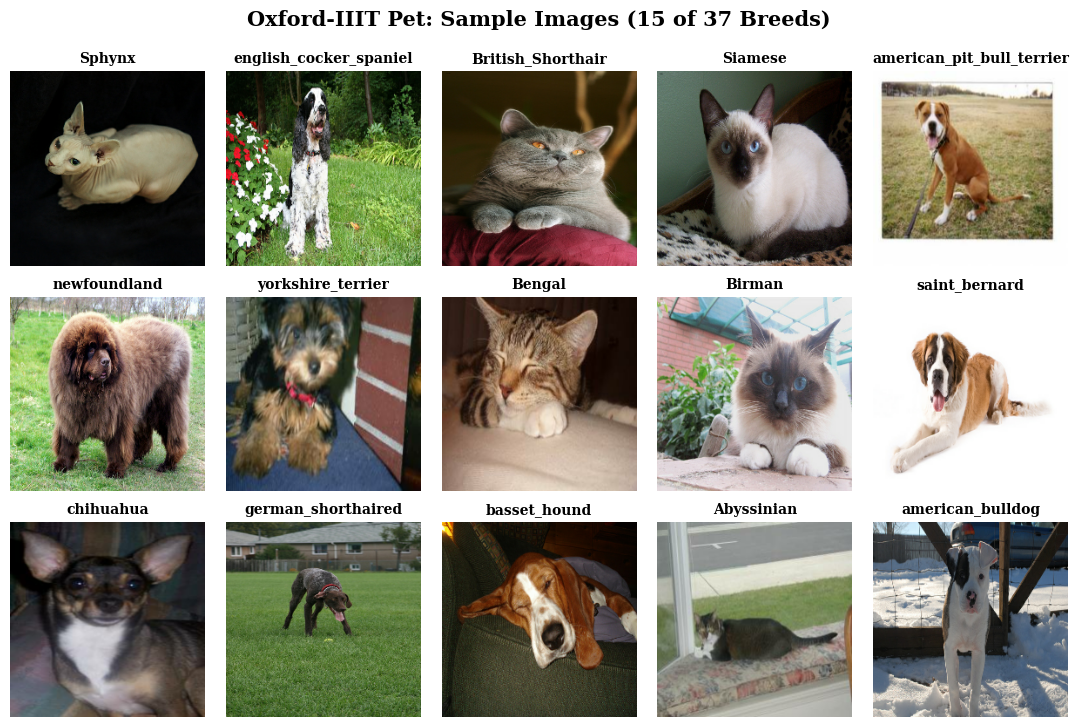

In [9]:
"""
Display one sample image per class for a subset of breeds, and the overall class
balance across the training and testing splits.
"""
sample_images, sample_captions = [], []
seen = set()
for img, label in zip(X_train_img, y_train_full):
    if label not in seen:
        sample_images.append(img)
        sample_captions.append(CLASS_NAMES[label])
        seen.add(label)
    if len(seen) == 15:
        break

fig = plot_image_grid(sample_images, sample_captions, ncols=5,
                       suptitle="Oxford-IIIT Pet: Sample Images (15 of 37 Breeds)")
save_figure(fig, "01_sample_images")
plt.show()

Saved: figures/02_class_distribution.eps


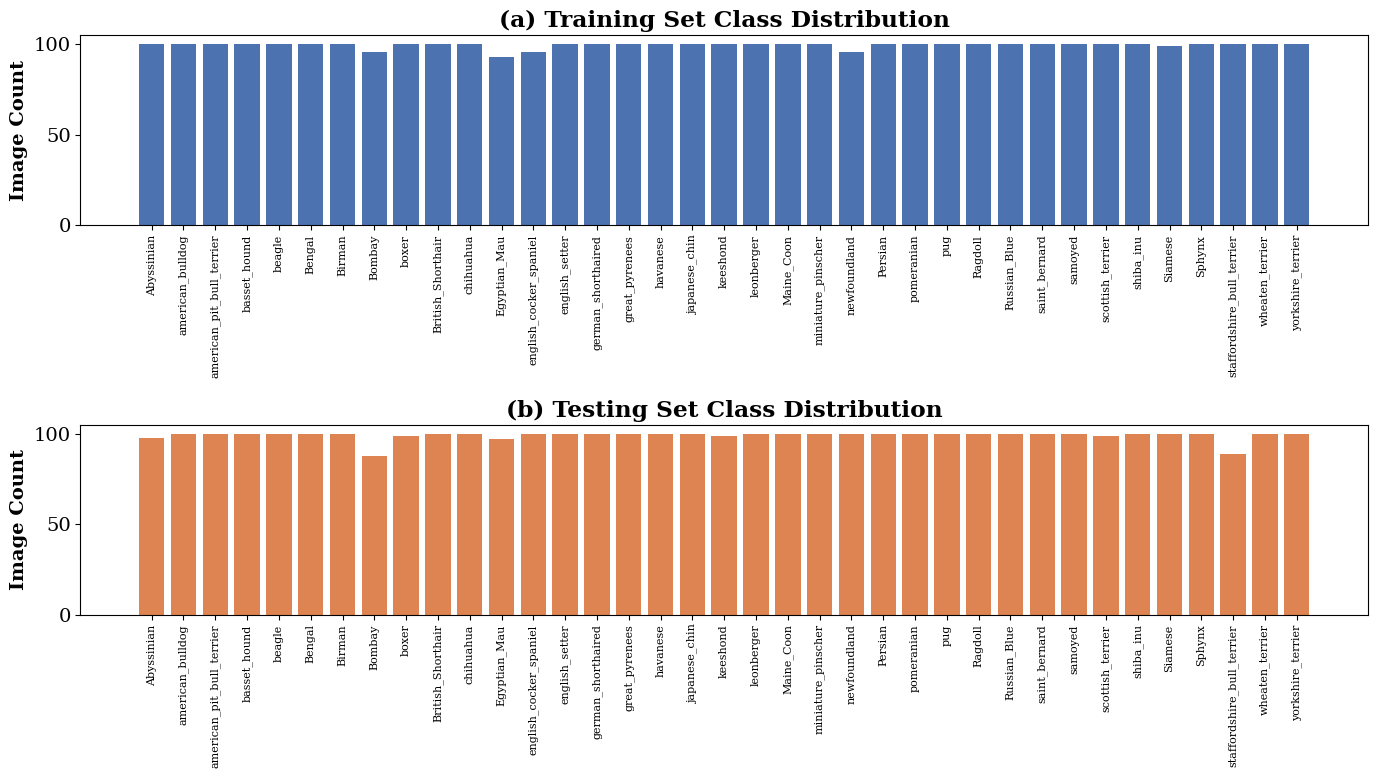

In [10]:
"""
Plot the number of images per breed class in the training and testing splits.
"""
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].bar(range(NUM_CLASSES), train_counts.reindex(range(NUM_CLASSES), fill_value=0), color="#4C72B0")
axes[0].set_xticks(range(NUM_CLASSES)); axes[0].set_xticklabels(CLASS_NAMES, rotation=90, fontsize=8)
axes[0].set_title("(a) Training Set Class Distribution"); axes[0].set_ylabel("Image Count")

axes[1].bar(range(NUM_CLASSES), test_counts.reindex(range(NUM_CLASSES), fill_value=0), color="#DD8452")
axes[1].set_xticks(range(NUM_CLASSES)); axes[1].set_xticklabels(CLASS_NAMES, rotation=90, fontsize=8)
axes[1].set_title("(b) Testing Set Class Distribution"); axes[1].set_ylabel("Image Count")

fig.tight_layout()
save_figure(fig, "02_class_distribution")
plt.show()

## Section 4: MobileNetV2 Architecture

Saved: figures/03_mobilenetv2_diagram.eps


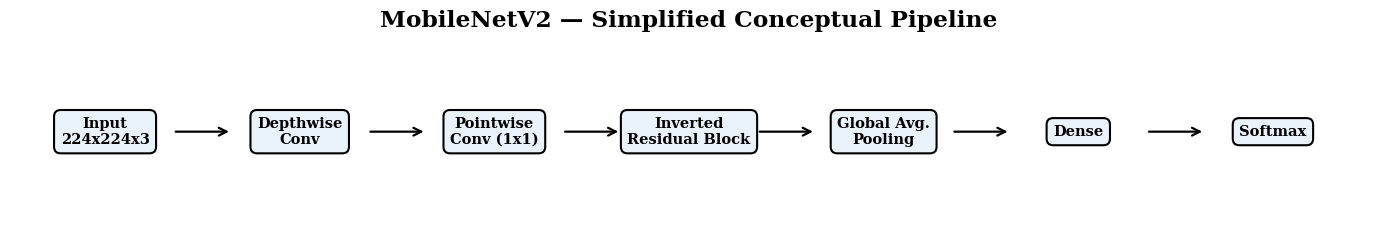

In [11]:
"""
Simplified conceptual diagram of the MobileNetV2 pipeline used in this experiment
(as given in the manual): a schematic, not the full architecture.
"""
steps = ["Input\n224x224x3", "Depthwise\nConv", "Pointwise\nConv (1x1)",
         "Inverted\nResidual Block", "Global Avg.\nPooling", "Dense", "Softmax"]

fig, ax = plt.subplots(figsize=(14, 2.6))
ax.axis("off")
xs = np.linspace(0.07, 0.93, len(steps))
for x, label in zip(xs, steps):
    ax.text(x, 0.5, label, ha="center", va="center", fontsize=10.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.45", facecolor="#EAF2FB",
                      edgecolor="black", linewidth=1.5),
            transform=ax.transAxes)
for x1, x2 in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(x2 - 0.05, 0.5), xytext=(x1 + 0.05, 0.5),
                xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(arrowstyle="->", lw=1.6))
ax.set_title("MobileNetV2 — Simplified Conceptual Pipeline")
fig.tight_layout()
save_figure(fig, "03_mobilenetv2_diagram")
plt.show()

## Section 4.1: Frozen-Backbone Feature Caching

Loads ImageNet-pretrained MobileNetV2 once, freezes it, and pre-computes its
Global-Average-Pooled output (1280-dim) for every training and testing image. Every
Tier-1 study below (Sections 5, 6, 8, 9, and Section 10 Case A) then trains only a small
head on these cached vectors instead of re-running the frozen backbone each time.

In [12]:
"""
Build the frozen MobileNetV2 feature extractor and cache features for the full
training split and the held-out test split.
"""
feature_extractor = tf.keras.applications.MobileNetV2(
    include_top=False, weights="imagenet", pooling="avg",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
feature_extractor.trainable = False
print(f"Feature extractor total layers: {len(feature_extractor.layers)}")


def extract_features(X_u8, batch_size=64):
    """Run the frozen feature extractor over `X_u8` and return a (N, 1280) numpy array."""
    ds = tf.data.Dataset.from_tensor_slices(X_u8).batch(batch_size)
    ds = ds.map(lambda x: mobilenet_v2.preprocess_input(tf.cast(x, tf.float32)),
                num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    return feature_extractor.predict(ds, verbose=0)


start = time.time()
X_train_feat = extract_features(X_train_img)
X_test_feat = extract_features(X_test_img)
print(f"Feature extraction time: {time.time() - start:.1f} s")
print(f"X_train_feat: {X_train_feat.shape}, X_test_feat: {X_test_feat.shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Feature extractor total layers: 155
Feature extraction time: 50.2 s
X_train_feat: (3680, 1280), X_test_feat: (3669, 1280)


In [13]:
"""
Split the cached training features into a head-train / head-val set (stratified) for
the Tier-1 comparison studies in Sections 5, 6, 8 and 9.
"""
Xh_train, Xh_val, yh_train, yh_val = train_test_split(
    X_train_feat, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full
)
print(f"Head-train: {Xh_train.shape}, Head-val: {Xh_val.shape}")

Head-train: (2944, 1280), Head-val: (736, 1280)


### Shared Model-Building Utilities (used across Sections 5, 6, 8, 9)

In [14]:
"""
Reusable builders for the Tier-1 classifier head (trained on cached 1280-dim MobileNetV2
features) and for Keras optimizer instances by name.
"""
INIT_MAP = {
    "zero": lambda: tf.keras.initializers.Zeros(),
    "random": lambda: tf.keras.initializers.RandomNormal(stddev=0.05, seed=SEED),
    "xavier": lambda: tf.keras.initializers.GlorotUniform(seed=SEED),
    "he": lambda: tf.keras.initializers.HeNormal(seed=SEED),
}


def build_head_model(feature_dim=FEATURE_DIM, num_classes=NUM_CLASSES, dense_units=256,
                      initializer="he", use_l2=False, l2_lambda=1e-3,
                      use_dropout=False, dropout_rate=0.5, use_batchnorm=False):
    """Build a small classifier head that operates on precomputed MobileNetV2 features."""
    kernel_init = INIT_MAP[initializer]()
    kernel_reg = tf.keras.regularizers.l2(l2_lambda) if use_l2 else None

    inputs = layers.Input(shape=(feature_dim,))
    x = layers.Dense(dense_units, kernel_initializer=kernel_init, kernel_regularizer=kernel_reg)(inputs)
    if use_batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if use_dropout:
        x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax",
                            kernel_initializer=INIT_MAP[initializer]())(x)
    return models.Model(inputs, outputs)


def build_optimizer(name, learning_rate=0.001):
    """Return a configured Keras optimizer instance by name."""
    optimizer_map = {
        "sgd": tf.keras.optimizers.SGD(learning_rate=learning_rate),
        "momentum": tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9),
        "rmsprop": tf.keras.optimizers.RMSprop(learning_rate=learning_rate),
        "adam": tf.keras.optimizers.Adam(learning_rate=learning_rate),
    }
    return optimizer_map[name]


def train_head(model, optimizer_name="adam", learning_rate=0.001, batch_size=32,
               epochs=15, x_train=None, y_train=None, x_val=None, y_val=None, verbose=0):
    """Compile and train a head model on cached features; return (history, elapsed_seconds).
    If x_val/y_val are None, trains without a validation_data split (used for final
    retraining, where no other split should be monitored during .fit())."""
    model.compile(optimizer=build_optimizer(optimizer_name, learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    fit_kwargs = dict(batch_size=batch_size, epochs=epochs, verbose=verbose)
    if x_val is not None and y_val is not None:
        fit_kwargs["validation_data"] = (x_val, y_val)
    start = time.time()
    hist = model.fit(x_train, y_train, **fit_kwargs)
    elapsed = time.time() - start
    return hist, elapsed


EPOCHS_STUDY = 15  # cheap on cached features, affordable for every Tier-1 comparison

## Section 5: Weight Initialization

Compares Zero, Random, Xavier/Glorot and He initialization for the new classifier head,
with the frozen MobileNetV2 backbone (and its cached features) held fixed.

In [15]:
"""
Train an identical head architecture under each of the four initialization strategies.
"""
init_histories, init_results = {}, []
for init_name in ["zero", "random", "xavier", "he"]:
    model = build_head_model(initializer=init_name)
    hist, elapsed = train_head(model, optimizer_name="adam", learning_rate=0.001,
                                epochs=EPOCHS_STUDY, x_train=Xh_train, y_train=yh_train,
                                x_val=Xh_val, y_val=yh_val)
    init_histories[init_name] = hist
    init_results.append({
        "Initializer": init_name,
        "Final Train Loss": hist.history["loss"][-1],
        "Best Val Accuracy": max(hist.history["val_accuracy"]),
        "Training Time (s)": elapsed,
    })
    print(f"{init_name}: best val acc = {max(hist.history['val_accuracy']):.4f}")

init_results_df = pd.DataFrame(init_results)
init_results_df

zero: best val acc = 0.0272
random: best val acc = 0.9049
xavier: best val acc = 0.9130
he: best val acc = 0.9171


,Initializer,Final Train Loss,Best Val Accuracy,Training Time (s)
0,zero,3.611211,0.027174,7.588446
1,random,0.002040,0.904891,6.334419
2,xavier,0.001522,0.913043,7.196917
3,he,0.001570,0.917120,6.341165


Saved: figures/04_init_training_loss.eps


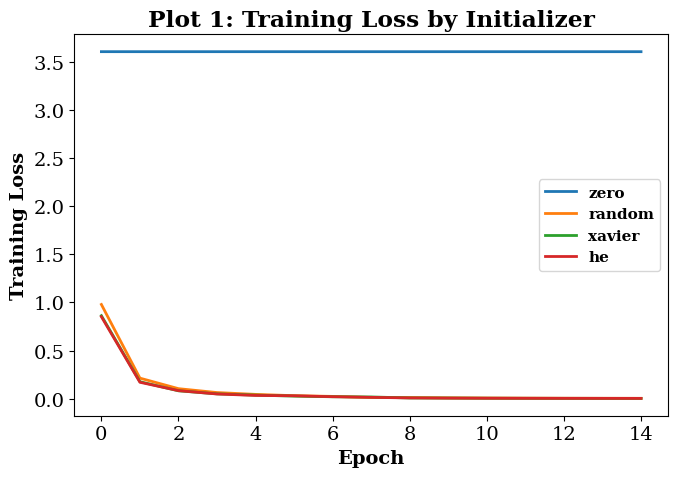

Saved: figures/05_init_val_accuracy.eps


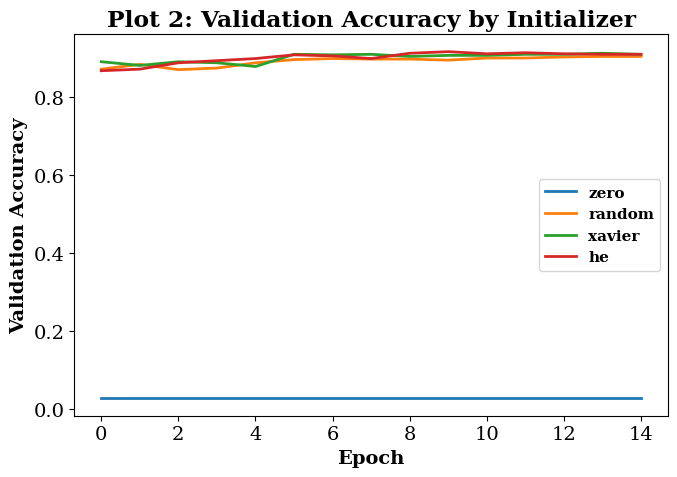

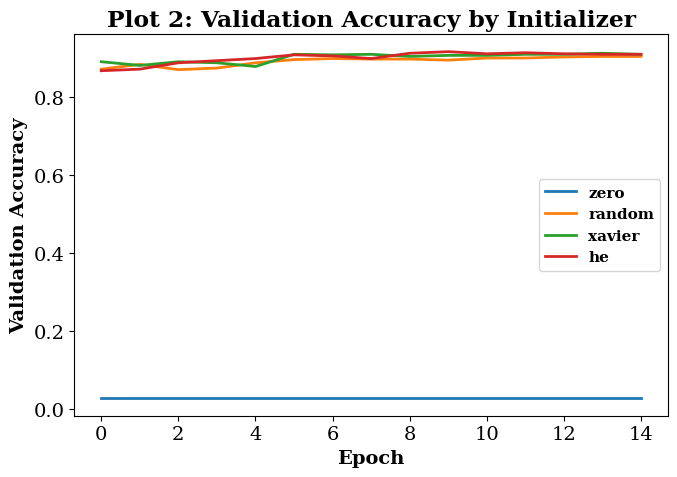

In [16]:
"""
Plot 1: training loss per initializer. Plot 2: validation accuracy per initializer.
"""
plot_metric_comparison(init_histories, "loss", "Plot 1: Training Loss by Initializer",
                        "Training Loss", "04_init_training_loss")
plot_metric_comparison(init_histories, "val_accuracy", "Plot 2: Validation Accuracy by Initializer",
                        "Validation Accuracy", "05_init_val_accuracy")

In [17]:
"""
Determine the best-performing initializer (by peak validation accuracy) for reuse as
the default in later sections.
"""
best_initializer = init_results_df.loc[init_results_df["Best Val Accuracy"].idxmax(), "Initializer"]
print(f"Best initializer: {best_initializer}")

Best initializer: he


## Section 6: Regularization and Overfitting

Compares No Regularization, L2, Dropout and Batch Normalization, using `best_initializer`
found in Section 5. Each variant gets its own train-vs-validation subplot (Plots 3 & 4),
clubbed into a single figure per the lab's plotting rules rather than one figure per variant.

In [18]:
"""
Train an identical head architecture under each of the four regularization strategies.
"""
REG_VARIANTS = {
    "No Regularization": dict(use_l2=False, use_dropout=False, use_batchnorm=False),
    "L2": dict(use_l2=True, l2_lambda=1e-3, use_dropout=False, use_batchnorm=False),
    "Dropout": dict(use_l2=False, use_dropout=True, dropout_rate=0.5, use_batchnorm=False),
    "Batch Normalization": dict(use_l2=False, use_dropout=False, use_batchnorm=True),
}

reg_histories, reg_results = {}, []
for name, overrides in REG_VARIANTS.items():
    model = build_head_model(initializer=best_initializer, **overrides)
    hist, elapsed = train_head(model, optimizer_name="adam", learning_rate=0.001,
                                epochs=EPOCHS_STUDY, x_train=Xh_train, y_train=yh_train,
                                x_val=Xh_val, y_val=yh_val)
    reg_histories[name] = hist
    reg_results.append({
        "Regularization": name,
        "Final Train Acc": hist.history["accuracy"][-1],
        "Best Val Accuracy": max(hist.history["val_accuracy"]),
        "Generalization Gap": hist.history["accuracy"][-1] - hist.history["val_accuracy"][-1],
        "Training Time (s)": elapsed,
    })
    print(f"{name}: best val acc = {max(hist.history['val_accuracy']):.4f}")

reg_results_df = pd.DataFrame(reg_results)
reg_results_df

No Regularization: best val acc = 0.9171
L2: best val acc = 0.9171
Dropout: best val acc = 0.9158
Batch Normalization: best val acc = 0.9117


,Regularization,Final Train Acc,Best Val Accuracy,Generalization Gap,Training Time (s)
0,No Regularization,1.000000,0.917120,0.089674,7.339381
1,L2,0.964674,0.917120,0.077446,7.553361
2,Dropout,0.981997,0.915761,0.068954,7.200820
3,Batch Normalization,1.000000,0.911685,0.089674,7.957522


Saved: figures/06_regularization_accuracy_grid.eps


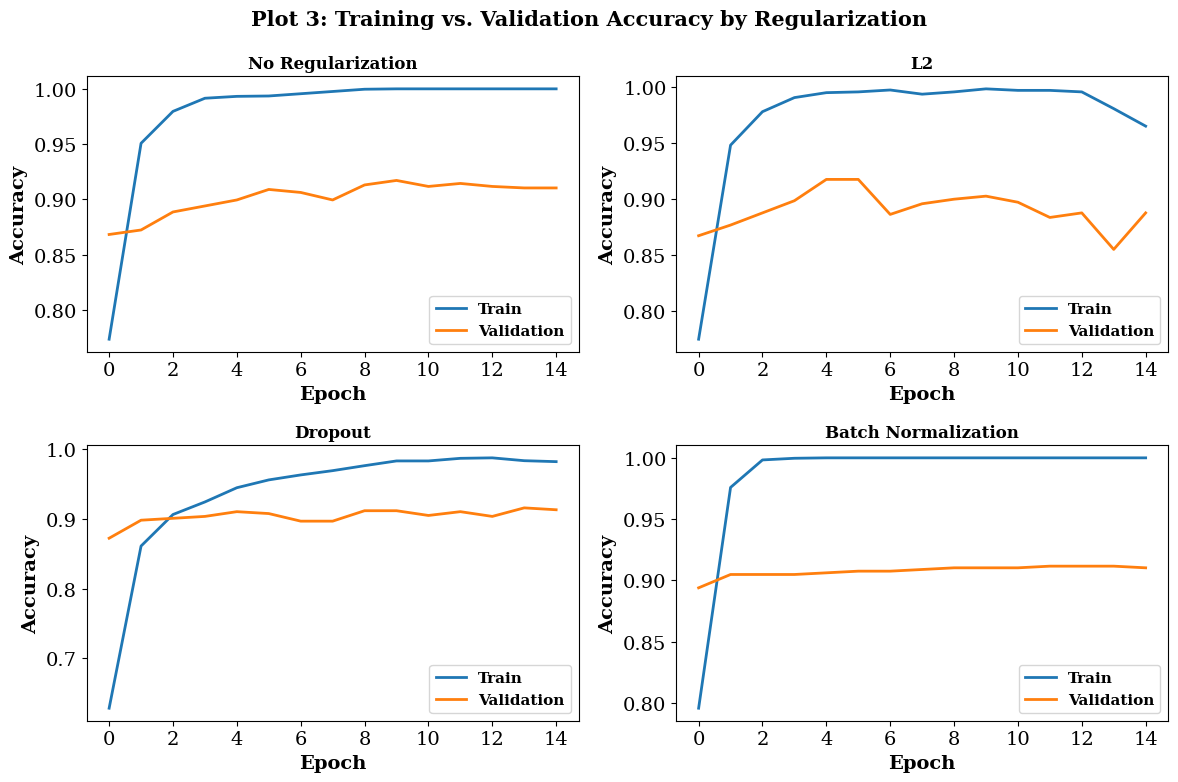

Saved: figures/07_regularization_loss_grid.eps


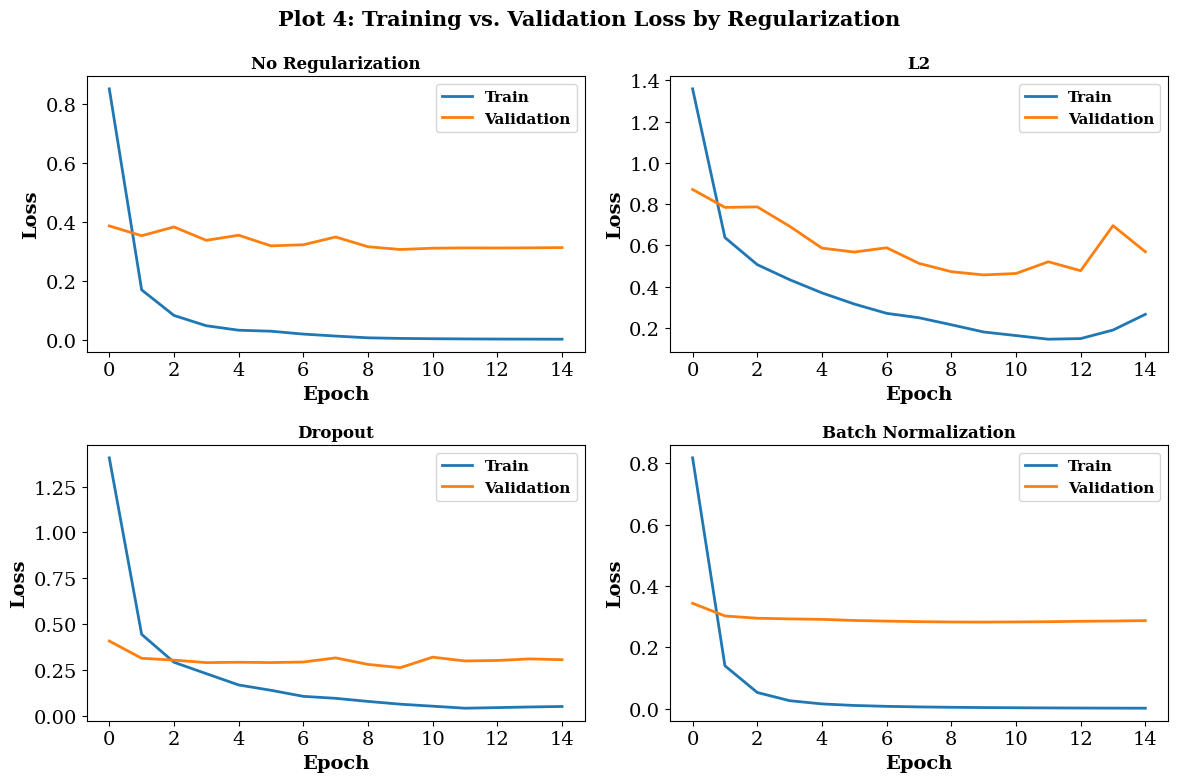

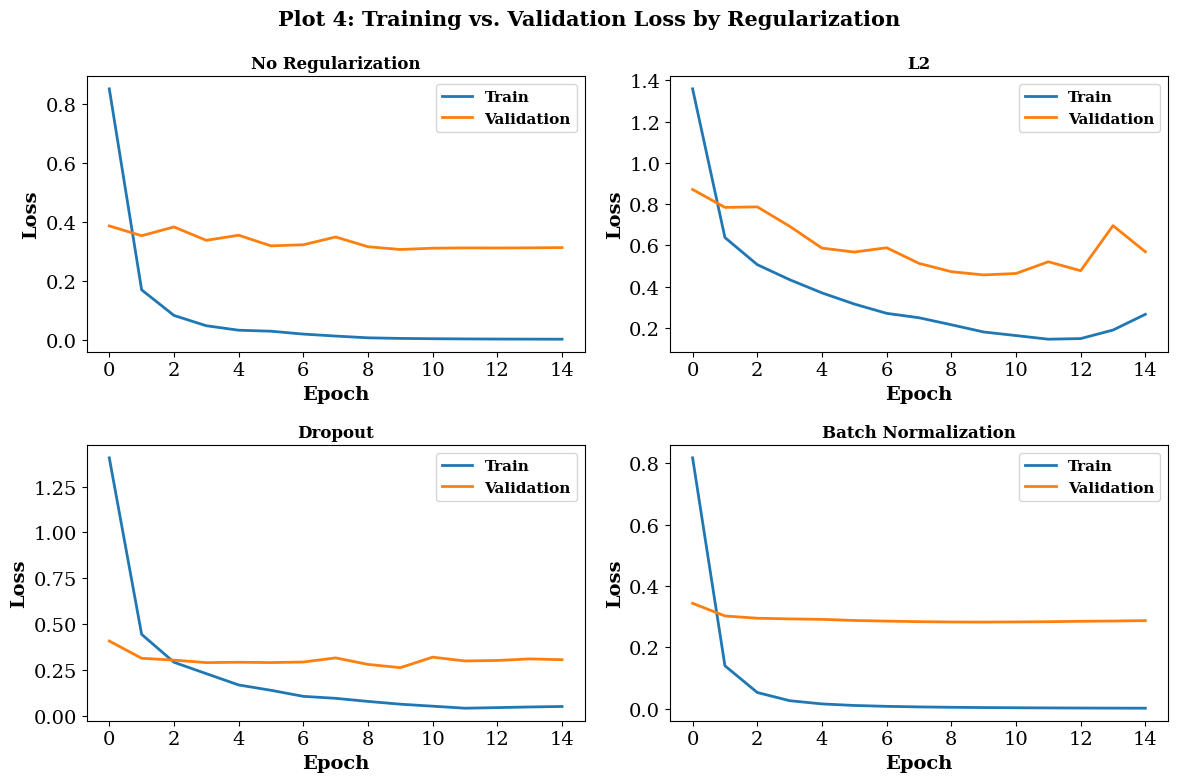

In [19]:
"""
Plot 3: training vs. validation accuracy, one subplot per regularization variant.
Plot 4: training vs. validation loss, one subplot per regularization variant.
"""
plot_train_val_grid(reg_histories, ("accuracy", "val_accuracy"),
                     "Plot 3: Training vs. Validation Accuracy by Regularization",
                     "06_regularization_accuracy_grid")
plot_train_val_grid(reg_histories, ("loss", "val_loss"),
                     "Plot 4: Training vs. Validation Loss by Regularization",
                     "07_regularization_loss_grid")

In [20]:
"""
Determine the best-performing regularization strategy for reuse as the default in later
sections.
"""
best_regularization = reg_results_df.loc[reg_results_df["Best Val Accuracy"].idxmax(), "Regularization"]
print(f"Best regularization: {best_regularization}")

Best regularization: No Regularization


## Section 7: Batch Normalization

In [21]:
"""
Numerically verify the manual's worked Batch Normalization example: mean, variance
and the normalized activations for a single mini-batch x = [2, 4, 6, 8].
"""
x = np.array([2.0, 4.0, 6.0, 8.0])
mu_B = x.mean()
var_B = x.var()  # population variance (ddof=0), matching the manual's formula
x_hat = (x - mu_B) / np.sqrt(var_B + 1e-8)

print(f"Batch: {x}")
print(f"Mean (mu_B): {mu_B}")
print(f"Variance (sigma_B^2): {var_B}")
print(f"Normalized (x_hat): {np.round(x_hat, 3)}")

Batch: [2. 4. 6. 8.]
Mean (mu_B): 5.0
Variance (sigma_B^2): 5.0
Normalized (x_hat): [-1.342 -0.447  0.447  1.342]


Saved: figures/08_bn_comparison.eps


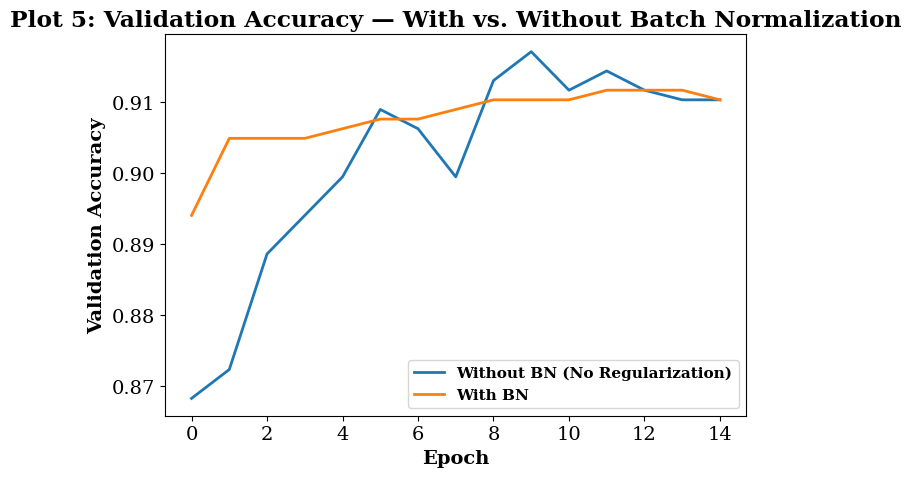

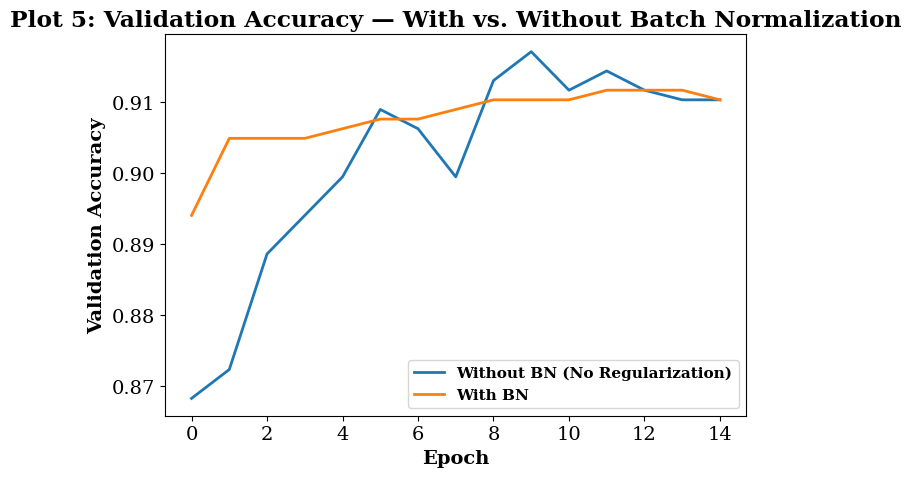

In [22]:
"""
Plot 5: validation accuracy with vs. without Batch Normalization, reusing the relevant
runs already trained in Section 6 rather than repeating them.
"""
bn_comparison = {
    "Without BN (No Regularization)": reg_histories["No Regularization"],
    "With BN": reg_histories["Batch Normalization"],
}
plot_metric_comparison(bn_comparison, "val_accuracy",
                        "Plot 5: Validation Accuracy — With vs. Without Batch Normalization",
                        "Validation Accuracy", "08_bn_comparison")

## Section 8: Optimization Algorithms

Compares SGD, Momentum, RMSProp and Adam, using `best_initializer` and
`best_regularization` from Sections 5–6.

In [23]:
"""
Train an identical head architecture under each of the four optimizers.
"""
BEST_REG_KWARGS = {
    "No Regularization": dict(use_l2=False, use_dropout=False, use_batchnorm=False),
    "L2": dict(use_l2=True, l2_lambda=1e-3, use_dropout=False, use_batchnorm=False),
    "Dropout": dict(use_l2=False, use_dropout=True, dropout_rate=0.5, use_batchnorm=False),
    "Batch Normalization": dict(use_l2=False, use_dropout=False, use_batchnorm=True),
}[best_regularization]

opt_histories, opt_results = {}, []
for opt_name in ["sgd", "momentum", "rmsprop", "adam"]:
    model = build_head_model(initializer=best_initializer, **BEST_REG_KWARGS)
    hist, elapsed = train_head(model, optimizer_name=opt_name, learning_rate=0.001,
                                epochs=EPOCHS_STUDY, x_train=Xh_train, y_train=yh_train,
                                x_val=Xh_val, y_val=yh_val)
    opt_histories[opt_name] = hist
    best_epoch = int(np.argmax(hist.history["val_accuracy"]))
    opt_results.append({
        "Optimizer": opt_name,
        "Final Loss": hist.history["loss"][-1],
        "Best Val Accuracy": max(hist.history["val_accuracy"]),
        "Epoch to Converge": best_epoch + 1,
        "Training Time (s)": elapsed,
    })
    print(f"{opt_name}: best val acc = {max(hist.history['val_accuracy']):.4f}")

opt_results_df = pd.DataFrame(opt_results)
opt_results_df

sgd: best val acc = 0.7908
momentum: best val acc = 0.9008
rmsprop: best val acc = 0.9198
adam: best val acc = 0.9171


,Optimizer,Final Loss,Best Val Accuracy,Epoch to Converge,Training Time (s)
0,sgd,1.180305,0.790761,15,6.930801
1,momentum,0.138091,0.900815,13,6.203378
2,rmsprop,0.000222,0.919837,10,7.037219
3,adam,0.001570,0.917120,10,6.510045


Saved: figures/09_optimizer_training_loss.eps


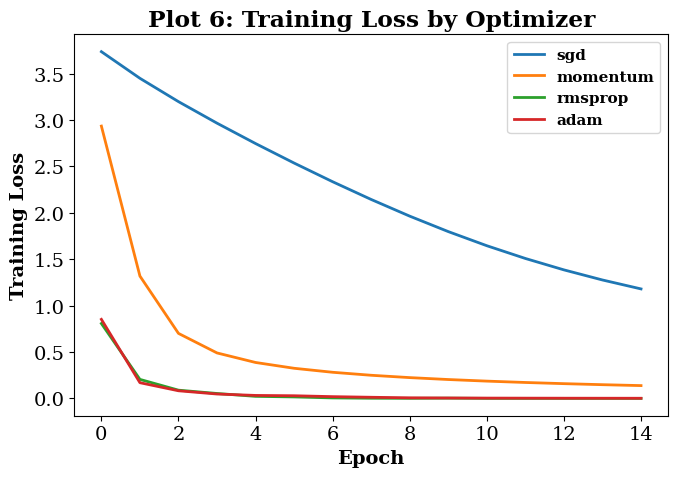

Saved: figures/10_optimizer_val_accuracy.eps


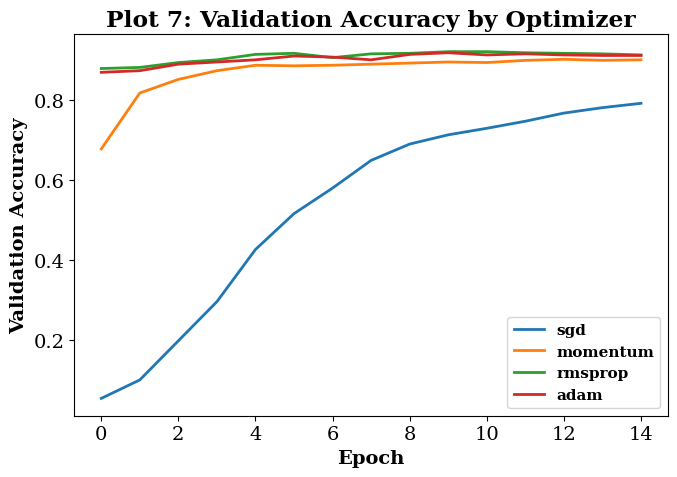

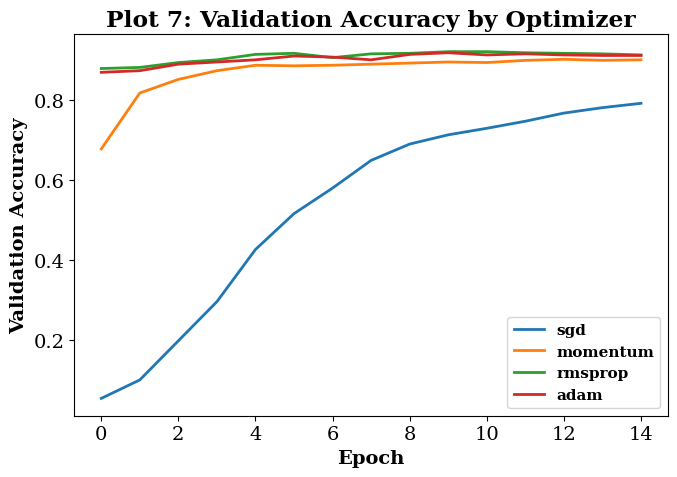

In [24]:
"""
Plot 6: training loss per optimizer. Plot 7: validation accuracy per optimizer.
"""
plot_metric_comparison(opt_histories, "loss", "Plot 6: Training Loss by Optimizer",
                        "Training Loss", "09_optimizer_training_loss")
plot_metric_comparison(opt_histories, "val_accuracy", "Plot 7: Validation Accuracy by Optimizer",
                        "Validation Accuracy", "10_optimizer_val_accuracy")

In [25]:
"""
Determine the best-performing optimizer for reuse as the default in later sections.
"""
best_optimizer = opt_results_df.loc[opt_results_df["Best Val Accuracy"].idxmax(), "Optimizer"]
print(f"Best optimizer: {best_optimizer}")

Best optimizer: rmsprop


## Section 9: CNN Hyperparameter Tuning

**Scope note:** the manual's hyperparameter table includes two rows — "Fine-Tuning
Learning Rate" and "Frozen Layers" — that only make sense once the backbone is actually
being unfrozen, so they are addressed in Section 10 (Case A = frozen base, Case B =
partial unfreezing at a small fine-tuning learning rate) rather than duplicated here.
This section sweeps Learning Rate, Batch Size, Dropout Rate and Optimizer as a
one-factor-at-a-time (OFAT) study, changing exactly one hyperparameter at a time per the
manual's stated rule. The regularization mode is fixed to Dropout here (rather than
inheriting Section 6's winner) since Dropout is the only regularizer with a continuously
tunable rate to sweep.

In [26]:
"""
Convolution output-size formula demo: O = floor((N + 2P - K) / S) + 1.
"""
def conv_output_size(N, K, P, S):
    """Return the spatial output size of a convolution given input size N, kernel K,
    padding P and stride S."""
    return (N + 2 * P - K) // S + 1

demo_configs = [
    {"N": 224, "K": 3, "P": 1, "S": 1},
    {"N": 224, "K": 3, "P": 1, "S": 2},
    {"N": 224, "K": 1, "P": 0, "S": 1},
    {"N": 112, "K": 3, "P": 1, "S": 2},
]
demo_df = pd.DataFrame(demo_configs)
demo_df["Output Size"] = demo_df.apply(lambda r: conv_output_size(r.N, r.K, r.P, r.S), axis=1)
demo_df

,N,K,P,S,Output Size
0,224,3,1,1,224
1,224,3,1,2,112
2,224,1,0,1,224
3,112,3,1,2,56


In [27]:
"""
One-factor-at-a-time hyperparameter sweep: a baseline configuration (using the winning
initializer and optimizer found above, with Dropout regularization) trained first, then
one setting changed at a time.
"""
HP_BASELINE = dict(initializer=best_initializer, use_dropout=True, dropout_rate=0.5,
                    use_l2=False, use_batchnorm=False,
                    optimizer=best_optimizer, learning_rate=0.001, batch_size=32)

HP_RUNS = {
    "Baseline": {},
    "LR=0.0001": dict(learning_rate=0.0001),
    "Batch=16": dict(batch_size=16),
    "Batch=64": dict(batch_size=64),
    "Dropout=0.0": dict(dropout_rate=0.0),
    "Dropout=0.25": dict(dropout_rate=0.25),
    "Optimizer=SGD": dict(optimizer="sgd"),
}

hp_histories, hp_results = {}, []
for run_name, overrides in HP_RUNS.items():
    cfg = {**HP_BASELINE, **overrides}
    model = build_head_model(initializer=cfg["initializer"], use_dropout=cfg["use_dropout"],
                              dropout_rate=cfg["dropout_rate"], use_l2=cfg["use_l2"],
                              use_batchnorm=cfg["use_batchnorm"])
    hist, elapsed = train_head(model, optimizer_name=cfg["optimizer"],
                                learning_rate=cfg["learning_rate"], batch_size=cfg["batch_size"],
                                epochs=EPOCHS_STUDY, x_train=Xh_train, y_train=yh_train,
                                x_val=Xh_val, y_val=yh_val)
    hp_histories[run_name] = hist
    hp_results.append({"Run": run_name, **cfg, "Best Val Accuracy": max(hist.history["val_accuracy"])})
    print(f"{run_name}: best val acc = {max(hist.history['val_accuracy']):.4f}")

hp_results_df = pd.DataFrame(hp_results)
hp_results_df

Baseline: best val acc = 0.9226
LR=0.0001: best val acc = 0.9103
Batch=16: best val acc = 0.9171
Batch=64: best val acc = 0.9158
Dropout=0.0: best val acc = 0.9198
Dropout=0.25: best val acc = 0.9144
Optimizer=SGD: best val acc = 0.7595


,Run,initializer,use_dropout,dropout_rate,use_l2,use_batchnorm,optimizer,learning_rate,batch_size,Best Val Accuracy
0,Baseline,he,True,0.50,False,False,rmsprop,0.0010,32,0.922554
1,LR=0.0001,he,True,0.50,False,False,rmsprop,0.0001,32,0.910326
2,Batch=16,he,True,0.50,False,False,rmsprop,0.0010,16,0.917120
3,Batch=64,he,True,0.50,False,False,rmsprop,0.0010,64,0.915761
4,Dropout=0.0,he,True,0.00,False,False,rmsprop,0.0010,32,0.919837
5,Dropout=0.25,he,True,0.25,False,False,rmsprop,0.0010,32,0.914402
6,Optimizer=SGD,he,True,0.50,False,False,sgd,0.0010,32,0.759511


Saved: figures/11_hyperparameter_sweeps.eps


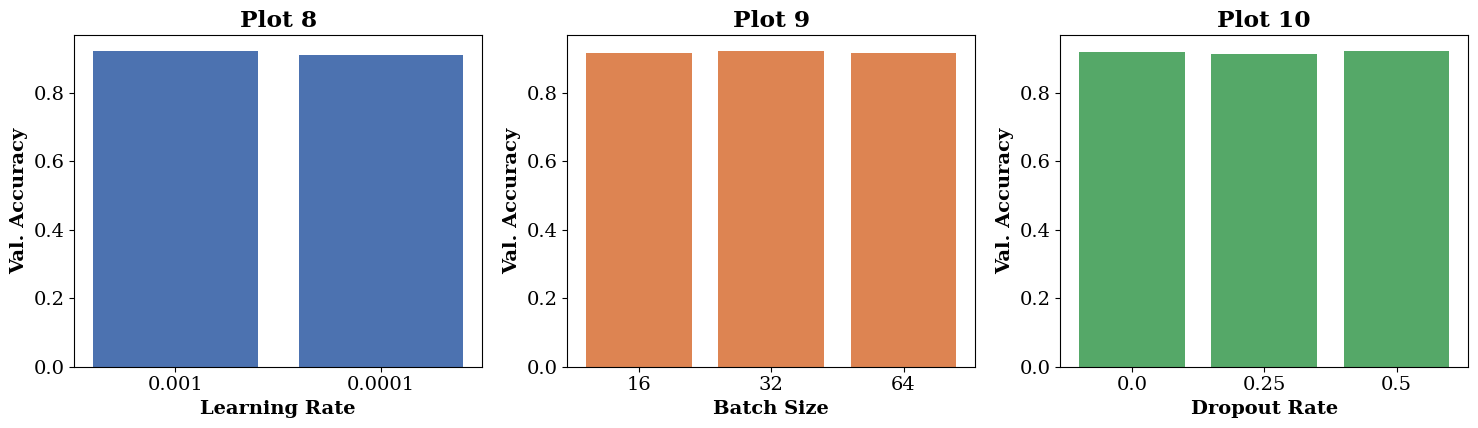

In [28]:
"""
Plot 8: learning rate vs. validation accuracy. Plot 9: batch size vs. validation
accuracy. Plot 10: dropout rate vs. validation accuracy.
"""
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

lr_rows = hp_results_df[hp_results_df["Run"].isin(["Baseline", "LR=0.0001"])]
axes[0].bar(lr_rows["learning_rate"].astype(str), lr_rows["Best Val Accuracy"], color="#4C72B0")
axes[0].set_xlabel("Learning Rate"); axes[0].set_ylabel("Val. Accuracy"); axes[0].set_title("Plot 8")

batch_rows = hp_results_df[hp_results_df["Run"].isin(["Baseline", "Batch=16", "Batch=64"])]
batch_rows = batch_rows.sort_values("batch_size")
axes[1].bar(batch_rows["batch_size"].astype(str), batch_rows["Best Val Accuracy"], color="#DD8452")
axes[1].set_xlabel("Batch Size"); axes[1].set_ylabel("Val. Accuracy"); axes[1].set_title("Plot 9")

drop_rows = hp_results_df[hp_results_df["Run"].isin(["Baseline", "Dropout=0.0", "Dropout=0.25"])]
drop_rows = drop_rows.sort_values("dropout_rate")
axes[2].bar(drop_rows["dropout_rate"].astype(str), drop_rows["Best Val Accuracy"], color="#55A868")
axes[2].set_xlabel("Dropout Rate"); axes[2].set_ylabel("Val. Accuracy"); axes[2].set_title("Plot 10")

fig.tight_layout()
save_figure(fig, "11_hyperparameter_sweeps")
plt.show()

In [29]:
"""
Assemble the best value found for each individually-tuned hyperparameter into a single
combined configuration for reuse in Sections 10-12.
"""
best_lr = lr_rows.loc[lr_rows["Best Val Accuracy"].idxmax(), "learning_rate"]
best_batch = int(batch_rows.loc[batch_rows["Best Val Accuracy"].idxmax(), "batch_size"])
best_dropout = drop_rows.loc[drop_rows["Best Val Accuracy"].idxmax(), "dropout_rate"]
best_opt_hp = hp_results_df.loc[hp_results_df["Run"] == "Optimizer=SGD", "Best Val Accuracy"].values[0]
best_opt_final = "sgd" if best_opt_hp > hp_results_df.loc[hp_results_df["Run"] == "Baseline", "Best Val Accuracy"].values[0] else best_optimizer

BEST_HP_CONFIG = dict(
    initializer=best_initializer, use_dropout=True, dropout_rate=float(best_dropout),
    use_l2=False, use_batchnorm=False,
    optimizer=best_opt_final, learning_rate=float(best_lr), batch_size=best_batch,
)
print("Best Hyperparameters config:", BEST_HP_CONFIG)

Best Hyperparameters config: {'initializer': 'he', 'use_dropout': True, 'dropout_rate': 0.5, 'use_l2': False, 'use_batchnorm': False, 'optimizer': 'rmsprop', 'learning_rate': 0.001, 'batch_size': 32}


## Section 10: Transfer Learning and Fine-Tuning

**Case A (Feature Extraction):** the tuned head from Section 9 trained on the frozen
backbone's cached features — this section's "official" Case A run.
**Case B (Fine-Tuning):** the same head architecture, but MobileNetV2's last N layers are
unfrozen and trained end-to-end at a much smaller learning rate. This requires real
images (not cached features), since the backbone itself is now being updated.

In [30]:
"""
Case A: Feature Extraction. Train the Section-9 best-hyperparameter head on cached
features (frozen backbone).
"""
model_case_a = build_head_model(initializer=BEST_HP_CONFIG["initializer"],
                                 use_dropout=BEST_HP_CONFIG["use_dropout"],
                                 dropout_rate=BEST_HP_CONFIG["dropout_rate"],
                                 use_l2=BEST_HP_CONFIG["use_l2"],
                                 use_batchnorm=BEST_HP_CONFIG["use_batchnorm"])
history_case_a, time_case_a = train_head(
    model_case_a, optimizer_name=BEST_HP_CONFIG["optimizer"],
    learning_rate=BEST_HP_CONFIG["learning_rate"], batch_size=BEST_HP_CONFIG["batch_size"],
    epochs=EPOCHS_STUDY, x_train=Xh_train, y_train=yh_train, x_val=Xh_val, y_val=yh_val,
)
print(f"Case A (Feature Extraction) best val acc: {max(history_case_a.history['val_accuracy']):.4f}, "
      f"time: {time_case_a:.1f} s")

Case A (Feature Extraction) best val acc: 0.9185, time: 8.3 s


In [31]:
"""
Build an end-to-end MobileNetV2 classifier, optionally unfreezing its last N layers for
fine-tuning. Batch Normalization layers inside the backbone are kept in inference mode
(`training=False`) even when unfrozen, which is standard practice to avoid destabilizing
their running statistics during fine-tuning.
"""
def build_finetune_model(unfreeze_last_n=0, dense_units=256, initializer="he",
                          use_dropout=True, dropout_rate=0.5,
                          img_size=IMG_SIZE, num_classes=NUM_CLASSES):
    """Build a MobileNetV2-based classifier; unfreeze its last `unfreeze_last_n` layers."""
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", pooling="avg",
        input_shape=(img_size, img_size, 3),
    )
    base.trainable = unfreeze_last_n > 0
    if unfreeze_last_n > 0:
        for layer in base.layers[: len(base.layers) - unfreeze_last_n]:
            layer.trainable = False

    kernel_init = INIT_MAP[initializer]()
    inputs = layers.Input(shape=(img_size, img_size, 3))
    x = base(inputs, training=False)
    x = layers.Dense(dense_units, kernel_initializer=kernel_init)(x)
    x = layers.Activation("relu")(x)
    if use_dropout:
        x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax",
                            kernel_initializer=INIT_MAP[initializer]())(x)
    return models.Model(inputs, outputs), base


UNFREEZE_LAST_N = 30

_probe_base = tf.keras.applications.MobileNetV2(include_top=False, weights=None,
                                                 pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3))
print(f"MobileNetV2 feature-extractor total layers: {len(_probe_base.layers)}")
print(f"Unfreezing last {UNFREEZE_LAST_N} of those layers for fine-tuning.")
del _probe_base

MobileNetV2 feature-extractor total layers: 155
Unfreezing last 30 of those layers for fine-tuning.


In [32]:
"""
Case B: Fine-Tuning. Train the same head, but with the last UNFREEZE_LAST_N MobileNetV2
layers unfrozen, using real images and a small fine-tuning learning rate.
"""
FINETUNE_LR = 1e-5
EPOCHS_FINETUNE = 8

Xf_train, Xf_val, yf_train, yf_val = train_test_split(
    X_train_img, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full
)
finetune_train_ds = make_image_dataset(Xf_train, yf_train, batch_size=BEST_HP_CONFIG["batch_size"], shuffle=True)
finetune_val_ds = make_image_dataset(Xf_val, yf_val, batch_size=BEST_HP_CONFIG["batch_size"], shuffle=False)

model_case_b, base_case_b = build_finetune_model(
    unfreeze_last_n=UNFREEZE_LAST_N, initializer=BEST_HP_CONFIG["initializer"],
    use_dropout=BEST_HP_CONFIG["use_dropout"], dropout_rate=BEST_HP_CONFIG["dropout_rate"],
)
model_case_b.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=FINETUNE_LR),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_case_b = model_case_b.fit(finetune_train_ds, validation_data=finetune_val_ds,
                                   epochs=EPOCHS_FINETUNE, verbose=1)
time_case_b = time.time() - start
print(f"Case B (Fine-Tuning) best val acc: {max(history_case_b.history['val_accuracy']):.4f}, "
      f"time: {time_case_b:.1f} s")

Epoch 1/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 92ms/step - accuracy: 0.0431 - loss: 3.9924 - val_accuracy: 0.1155 - val_loss: 3.3336
Epoch 2/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.1219 - loss: 3.3926 - val_accuracy: 0.2772 - val_loss: 2.8704
Epoch 3/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.2191 - loss: 2.9455 - val_accuracy: 0.4728 - val_loss: 2.4322
Epoch 4/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.3444 - loss: 2.5516 - val_accuracy: 0.6060 - val_loss: 2.0172
Epoch 5/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.4548 - loss: 2.1786 - val_accuracy: 0.6753 - val_loss: 1.6495
Epoch 6/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.5442 - loss: 1.8509 - val_accuracy: 0.7364 - val_loss: 1.3527
Epoch 7/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.6012 - loss: 1.6236 - val_accuracy: 0.7772 - val_loss: 1.1160
Epoch 8/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.6613 - loss: 1.3818 - val_accuracy: 0.8179 - val_loss

Saved: figures/12_case_a_vs_b_accuracy.eps


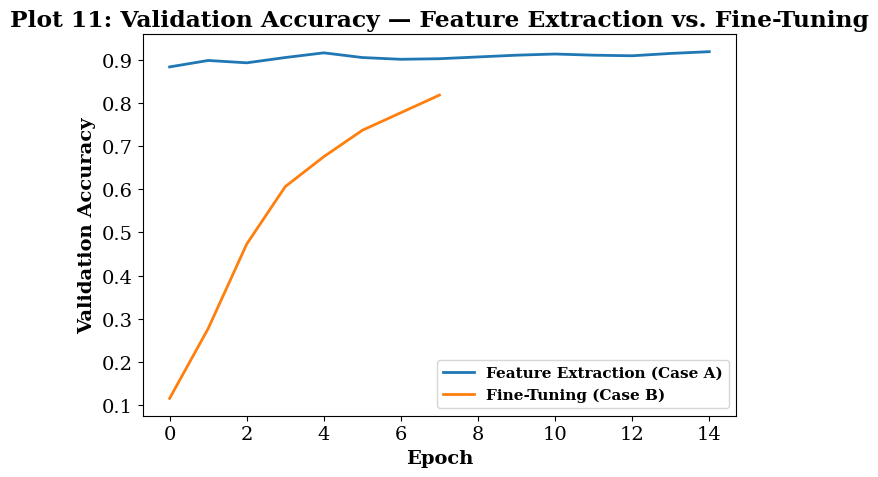

Saved: figures/13_case_a_vs_b_loss.eps


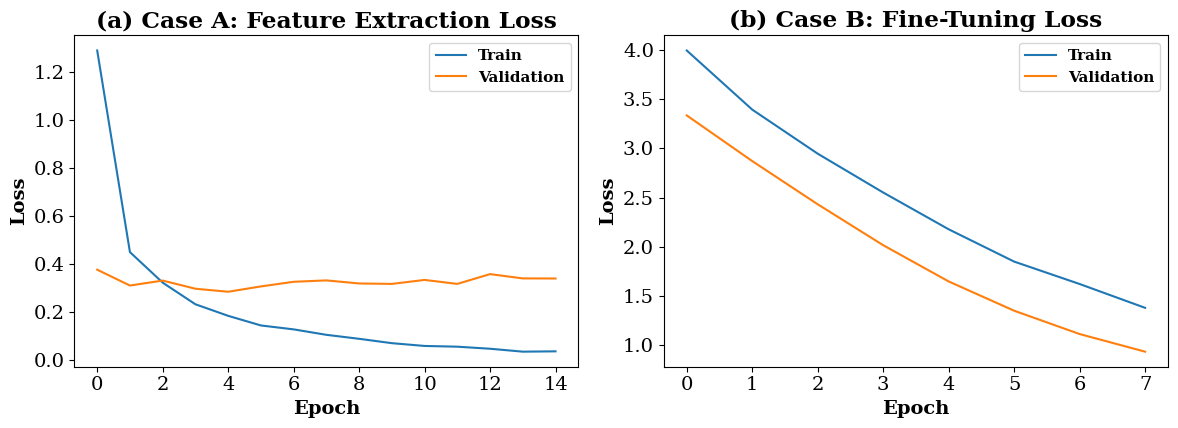

In [33]:
"""
Plot 11: validation accuracy, Feature Extraction vs. Fine-Tuning.
Plot 12: training and validation loss, Feature Extraction vs. Fine-Tuning.
"""
case_histories = {"Feature Extraction (Case A)": history_case_a, "Fine-Tuning (Case B)": history_case_b}
plot_metric_comparison(case_histories, "val_accuracy",
                        "Plot 11: Validation Accuracy — Feature Extraction vs. Fine-Tuning",
                        "Validation Accuracy", "12_case_a_vs_b_accuracy")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history_case_a.history["loss"], label="Train"); axes[0].plot(history_case_a.history["val_loss"], label="Validation")
axes[0].set_title("(a) Case A: Feature Extraction Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
bold_legend(axes[0])
axes[1].plot(history_case_b.history["loss"], label="Train"); axes[1].plot(history_case_b.history["val_loss"], label="Validation")
axes[1].set_title("(b) Case B: Fine-Tuning Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
bold_legend(axes[1])
fig.tight_layout()
save_figure(fig, "13_case_a_vs_b_loss")
plt.show()

## Section 11: K-Fold Cross-Validation

Four configurations are promoted to 5-fold stratified cross-validation on the training
split: **Baseline** (default head, frozen backbone), **Best Hyperparameters** (Section
9's tuned head, frozen backbone), **Fine-Tuned (default head)** (Case B's fine-tuning
applied to a default head), and **Fine-Tuned (best hyperparameters)** (fine-tuning
combined with the tuned head, testing whether the two gains stack).

In [34]:
"""
Run 5-fold cross-validation for a Tier-1 (frozen-backbone, cached-features) configuration.
"""
def run_cv_head_config(config, X_feat, y, k=5, epochs=10):
    """Stratified k-fold CV for a cached-features head configuration; returns fold accuracies."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    fold_accuracies = []
    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_feat, y)):
        model = build_head_model(initializer=config["initializer"], use_dropout=config["use_dropout"],
                                  dropout_rate=config["dropout_rate"], use_l2=config["use_l2"],
                                  use_batchnorm=config["use_batchnorm"])
        hist, _ = train_head(model, optimizer_name=config["optimizer"],
                              learning_rate=config["learning_rate"], batch_size=config["batch_size"],
                              epochs=epochs, x_train=X_feat[train_idx], y_train=y[train_idx],
                              x_val=X_feat[val_idx], y_val=y[val_idx])
        fold_acc = max(hist.history["val_accuracy"])
        fold_accuracies.append(fold_acc)
        print(f"  Fold {fold_idx + 1}/{k}: val acc = {fold_acc:.4f}")
    return fold_accuracies


def run_cv_finetune_config(config, X_img, y, k=5, epochs=5, unfreeze_last_n=UNFREEZE_LAST_N):
    """Stratified k-fold CV for a fine-tuning configuration; returns fold accuracies."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    fold_accuracies = []
    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_img, y)):
        train_ds = make_image_dataset(X_img[train_idx], y[train_idx],
                                       batch_size=config["batch_size"], shuffle=True)
        val_ds = make_image_dataset(X_img[val_idx], y[val_idx],
                                     batch_size=config["batch_size"], shuffle=False)
        model, _ = build_finetune_model(unfreeze_last_n=unfreeze_last_n,
                                         initializer=config["initializer"],
                                         use_dropout=config["use_dropout"],
                                         dropout_rate=config["dropout_rate"])
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=config["learning_rate"]),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0)
        fold_acc = max(hist.history["val_accuracy"])
        fold_accuracies.append(fold_acc)
        print(f"  Fold {fold_idx + 1}/{k}: val acc = {fold_acc:.4f}")
    return fold_accuracies

In [35]:
"""
Define the four CV configurations and run 5-fold cross-validation for each.
"""
BASELINE_CONFIG = dict(initializer="he", use_dropout=False, dropout_rate=0.5,
                        use_l2=False, use_batchnorm=False,
                        optimizer="adam", learning_rate=0.001, batch_size=32)

CV_CONFIGS = {
    "Baseline": {"type": "head", "params": BASELINE_CONFIG},
    "Best Hyperparameters": {"type": "head", "params": BEST_HP_CONFIG},
    "Fine-Tuned (default head)": {"type": "finetune", "params": {**BASELINE_CONFIG, "learning_rate": FINETUNE_LR}},
    "Fine-Tuned (best hyperparameters)": {"type": "finetune", "params": {**BEST_HP_CONFIG, "learning_rate": FINETUNE_LR}},
}

cv_fold_results = {}
for name, spec in CV_CONFIGS.items():
    print(f"Running CV for: {name}")
    if spec["type"] == "head":
        accs = run_cv_head_config(spec["params"], X_train_feat, y_train_full, k=5, epochs=10)
    else:
        accs = run_cv_finetune_config(spec["params"], X_train_img, y_train_full, k=5, epochs=5)
    cv_fold_results[name] = accs

Running CV for: Baseline
  Fold 1/5: val acc = 0.9185
  Fold 2/5: val acc = 0.9226
  Fold 3/5: val acc = 0.9171
  Fold 4/5: val acc = 0.9239
  Fold 5/5: val acc = 0.9158
Running CV for: Best Hyperparameters
  Fold 1/5: val acc = 0.9212
  Fold 2/5: val acc = 0.9253
  Fold 3/5: val acc = 0.9171
  Fold 4/5: val acc = 0.9212
  Fold 5/5: val acc = 0.9049
Running CV for: Fine-Tuned (default head)
  Fold 1/5: val acc = 0.8016
  Fold 2/5: val acc = 0.7731
  Fold 3/5: val acc = 0.7935
  Fold 4/5: val acc = 0.8166
  Fold 5/5: val acc = 0.7840
Running CV for: Fine-Tuned (best hyperparameters)
  Fold 1/5: val acc = 0.6739
  Fold 2/5: val acc = 0.6658
  Fold 3/5: val acc = 0.6793
  Fold 4/5: val acc = 0.6984
  Fold 5/5: val acc = 0.6726


In [36]:
"""
Assemble the 5-fold accuracy table (F1-F5, Mean +/- SD) for all four configurations.
"""
cv_table = pd.DataFrame(cv_fold_results).T
cv_table.columns = [f"F{i+1}" for i in range(5)]
cv_table["Mean"] = cv_table.mean(axis=1)
cv_table["SD"] = cv_table[[f"F{i+1}" for i in range(5)]].std(axis=1)
cv_table

,F1,F2,F3,F4,F5,Mean,SD
Baseline,0.918478,0.922554,0.917120,0.923913,0.915761,0.919565,0.003517
Best Hyperparameters,0.921196,0.925272,0.917120,0.921196,0.904891,0.917935,0.007841
Fine-Tuned (default head),0.801630,0.773098,0.793478,0.816576,0.783967,0.793750,0.016624
Fine-Tuned (best hyperparameters),0.673913,0.665761,0.679348,0.698370,0.672554,0.677989,0.012378


Saved: figures/14_cv_accuracy_comparison.eps


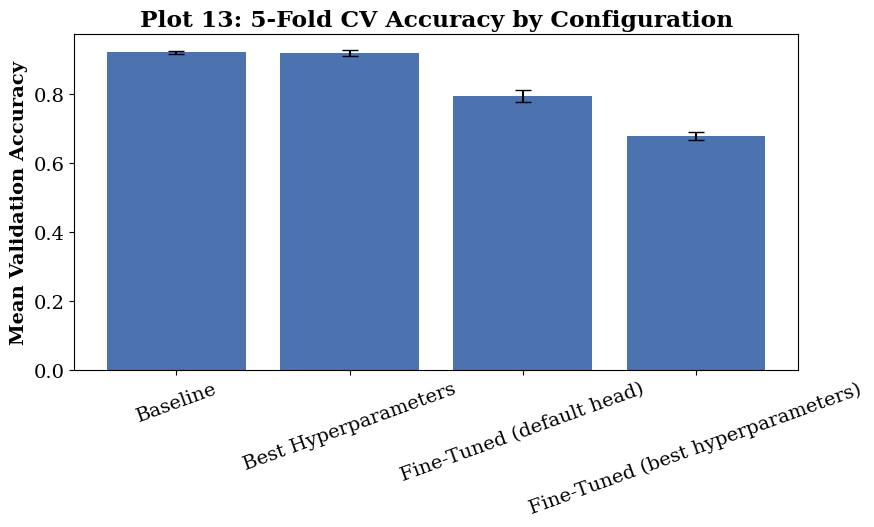

In [37]:
"""
Plot 13: mean 5-fold validation accuracy per configuration, with standard-deviation
error bars.
"""
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(cv_table.index, cv_table["Mean"], yerr=cv_table["SD"], capsize=6, color="#4C72B0")
ax.set_ylabel("Mean Validation Accuracy"); ax.set_title("Plot 13: 5-Fold CV Accuracy by Configuration")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_figure(fig, "14_cv_accuracy_comparison")
plt.show()

## Section 12: Final Model Evaluation

The configuration with the highest mean CV accuracy is retrained on the **complete**
training split (no folds held out) and evaluated once on the independent test split,
which has not been touched anywhere above.

In [38]:
"""
Shared no-leakage retrain/evaluate routine: trains a given configuration on the
complete training split with no validation_data (so the test split is never seen
during .fit()), then predicts on the held-out test split exactly once. Used for the
Section-12 final model and reused for the Section-16 additional-exercise configurations.
"""
def retrain_and_evaluate(config_type, params, unfreeze_last_n=UNFREEZE_LAST_N,
                          epochs_head=EPOCHS_STUDY, epochs_finetune=EPOCHS_FINETUNE):
    """Retrain `params` (type "head" or "finetune") on the full training split and
    evaluate once on X_test_feat/X_test_img, y_test. Returns
    (test_accuracy, test_f1_macro, elapsed_seconds, num_params, trained_model, y_pred)."""
    start = time.time()
    if config_type == "head":
        model = build_head_model(initializer=params["initializer"], use_dropout=params["use_dropout"],
                                  dropout_rate=params["dropout_rate"], use_l2=params["use_l2"],
                                  use_batchnorm=params["use_batchnorm"])
        train_head(model, optimizer_name=params["optimizer"], learning_rate=params["learning_rate"],
                   batch_size=params["batch_size"], epochs=epochs_head,
                   x_train=X_train_feat, y_train=y_train_full, verbose=1)
        y_probs = model.predict(X_test_feat, verbose=0)
    else:
        train_ds_full = make_image_dataset(X_train_img, y_train_full,
                                            batch_size=params["batch_size"], shuffle=True)
        test_ds_full = make_image_dataset(X_test_img, y_test,
                                           batch_size=params["batch_size"], shuffle=False)
        model, _ = build_finetune_model(unfreeze_last_n=unfreeze_last_n,
                                         initializer=params["initializer"],
                                         use_dropout=params["use_dropout"],
                                         dropout_rate=params["dropout_rate"])
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=params["learning_rate"]),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        model.fit(train_ds_full, epochs=epochs_finetune, verbose=1)
        y_probs = model.predict(test_ds_full, verbose=0)
    elapsed = time.time() - start

    y_pred = np.argmax(y_probs, axis=1)
    acc = accuracy_score(y_test, y_pred)
    _, _, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    return acc, f1_macro, elapsed, model.count_params(), model, y_pred

In [39]:
"""
Identify the winning configuration from cross-validation and retrain it on the full
training split using the no-leakage routine above.
"""
best_config_name = cv_table["Mean"].idxmax()
best_config_spec = CV_CONFIGS[best_config_name]
print(f"Winning configuration: {best_config_name}")
print(f"CV mean accuracy: {cv_table.loc[best_config_name, 'Mean']:.4f} "
      f"+/- {cv_table.loc[best_config_name, 'SD']:.4f}")

test_accuracy, f1, final_training_time, final_num_params, final_model, y_pred = retrain_and_evaluate(
    best_config_spec["type"], best_config_spec["params"], unfreeze_last_n=UNFREEZE_LAST_N)
print(f"Final retraining time: {final_training_time:.1f} s")

Winning configuration: Baseline
CV mean accuracy: 0.9196 +/- 0.0035
Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7883 - loss: 0.7539
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9457 - loss: 0.1733
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9791 - loss: 0.0822
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9924 - loss: 0.0432
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9948 - loss: 0.0314
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9965 - loss: 0.0201
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9954 - loss: 0.0196
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9951 - loss: 0.0191
Epoch 9/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0076
Epoch 10/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0045
Epoch 11/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997

In [40]:
"""
Full precision/recall/F1 breakdown for the final retrained model on the held-out test set.
"""
precision, recall, _, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
print(f"Test Accuracy:      {test_accuracy:.4f}")
print(f"Macro Precision:    {precision:.4f}")
print(f"Macro Recall:       {recall:.4f}")
print(f"Macro F1-score:     {f1:.4f}")

report_df = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASS_NAMES,
                                                output_dict=True)).transpose()
report_df

Test Accuracy:      0.8934
Macro Precision:    0.9015
Macro Recall:       0.8926
Macro F1-score:     0.8938


,precision,recall,f1-score,support
Abyssinian,0.833333,0.765306,0.797872,98.000000
american_bulldog,0.766355,0.820000,0.792271,100.000000
american_pit_bull_terrier,0.746988,0.620000,0.677596,100.000000
basset_hound,0.947917,0.910000,0.928571,100.000000
beagle,0.892157,0.910000,0.900990,100.000000
Bengal,0.539326,0.960000,0.690647,100.000000
Birman,0.801980,0.810000,0.805970,100.000000
Bombay,0.950000,0.863636,0.904762,88.000000
boxer,0.842593,0.919192,0.879227,99.000000
British_Shorthair,0.880435,0.810000,0.843750,100.000000


In [41]:
"""
Consolidated final metrics table.
"""
total_params = final_model.count_params()
final_metrics = pd.DataFrame({
    "Metric": ["Mean CV Accuracy", "CV Standard Deviation", "Test Accuracy",
               "Precision (macro)", "Recall (macro)", "F1-score (macro)",
               "Training Time (s)", "Number of Parameters"],
    "Value": [
        cv_table.loc[best_config_name, "Mean"],
        cv_table.loc[best_config_name, "SD"],
        test_accuracy, precision, recall, f1,
        final_training_time, total_params,
    ],
})
final_metrics

,Metric,Value
0,Mean CV Accuracy,0.919565
1,CV Standard Deviation,0.003517
2,Test Accuracy,0.893431
3,Precision (macro),0.901518
4,Recall (macro),0.892603
5,F1-score (macro),0.893842
6,Training Time (s),7.960466
7,Number of Parameters,337445.000000


Saved: figures/15_confusion_matrix.eps


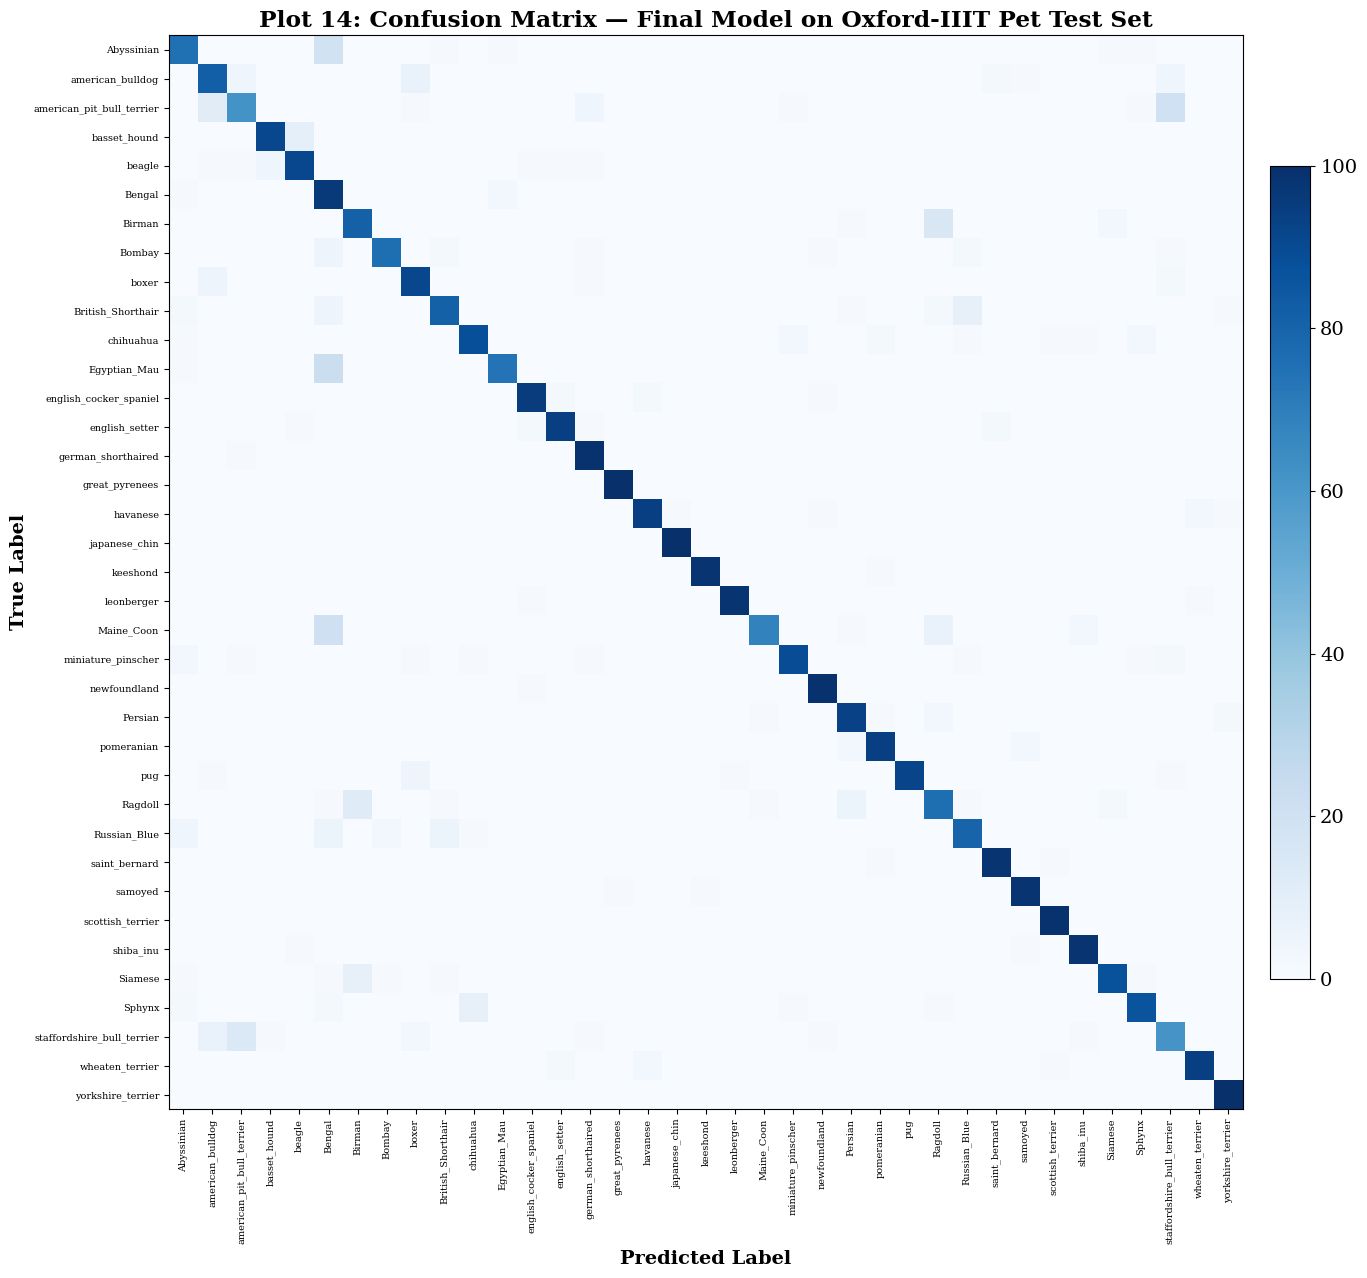

In [42]:
"""
Plot 14: confusion matrix on the test set. With 37 classes, per-cell counts are not
annotated (37x37 = 1369 cells); the color scale and class-name ticks carry the signal.
"""
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=7)
ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
ax.set_title("Plot 14: Confusion Matrix — Final Model on Oxford-IIIT Pet Test Set")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
fig.tight_layout()
save_figure(fig, "15_confusion_matrix")
plt.show()

Saved: figures/16_misclassified_samples.eps


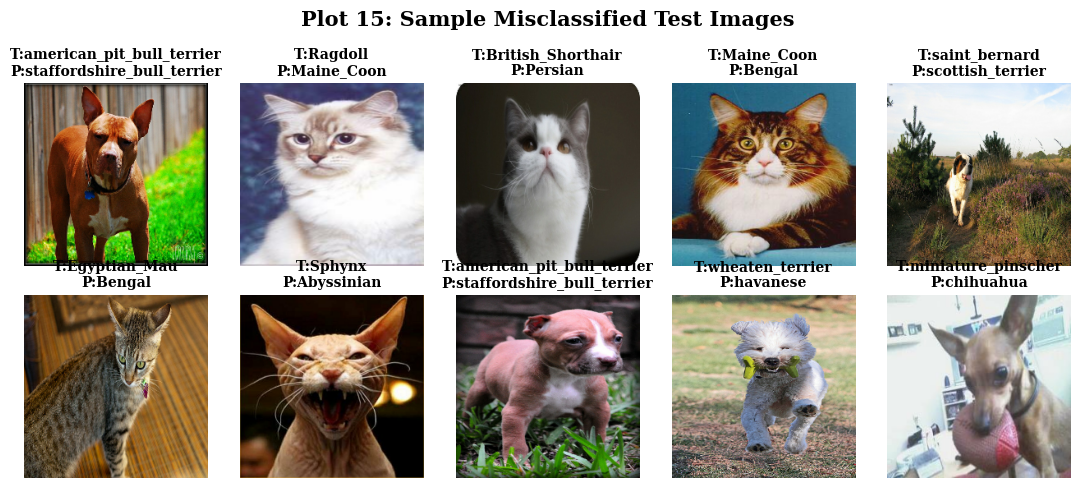

In [43]:
"""
Plot 15 (Optional): a sample of misclassified test images with true and predicted breeds.
"""
misclassified_idx = np.where(y_pred != y_test)[0]
n_show = min(10, len(misclassified_idx))
sample_idx = np.random.default_rng(SEED).choice(misclassified_idx, size=n_show, replace=False)

mis_images = [X_test_img[i] for i in sample_idx]
mis_captions = [f"T:{CLASS_NAMES[y_test[i]]}\nP:{CLASS_NAMES[y_pred[i]]}" for i in sample_idx]

fig = plot_image_grid(mis_images, mis_captions, ncols=5,
                       suptitle="Plot 15: Sample Misclassified Test Images")
save_figure(fig, "16_misclassified_samples")
plt.show()

## Section 13: Overall Results

In [44]:
"""
Consolidate every named configuration's result into the manual's summary table.
Single-study configurations (Best Initialization/Regularization/Optimizer) report their
own individual-study validation accuracy; the CV-promoted configurations report their
cross-validation mean, SD, and test accuracy where available.
"""
overall_results = pd.DataFrame([
    {"Configuration": "Baseline", "CV Accuracy": cv_table.loc["Baseline", "Mean"],
     "SD": cv_table.loc["Baseline", "SD"], "Test Accuracy": None, "Training Time (s)": None},
    {"Configuration": "Best Initialization", "CV Accuracy": None, "SD": None,
     "Test Accuracy": init_results_df["Best Val Accuracy"].max(), "Training Time (s)": None},
    {"Configuration": "Best Regularization", "CV Accuracy": None, "SD": None,
     "Test Accuracy": reg_results_df["Best Val Accuracy"].max(), "Training Time (s)": None},
    {"Configuration": "Best Optimizer", "CV Accuracy": None, "SD": None,
     "Test Accuracy": opt_results_df["Best Val Accuracy"].max(), "Training Time (s)": None},
    {"Configuration": "Best Hyperparameters", "CV Accuracy": cv_table.loc["Best Hyperparameters", "Mean"],
     "SD": cv_table.loc["Best Hyperparameters", "SD"], "Test Accuracy": None, "Training Time (s)": None},
    {"Configuration": "Fine-Tuned Model", "CV Accuracy": cv_table.loc[best_config_name, "Mean"],
     "SD": cv_table.loc[best_config_name, "SD"], "Test Accuracy": test_accuracy,
     "Training Time (s)": final_training_time},
])
overall_results

,Configuration,CV Accuracy,SD,Test Accuracy,Training Time (s)
0,Baseline,0.919565,0.003517,NaN,NaN
1,Best Initialization,NaN,NaN,0.917120,NaN
2,Best Regularization,NaN,NaN,0.917120,NaN
3,Best Optimizer,NaN,NaN,0.919837,NaN
4,Best Hyperparameters,0.917935,0.007841,NaN,NaN
5,Fine-Tuned Model,0.919565,0.003517,0.893431,7.960466


## Section 16: Additional Exercise

Two new combinations of learning rate, dropout rate, batch size and fine-tuning
strategy are evaluated with 5-fold cross-validation on the training split, then
retrained on the complete training split and evaluated once on the test split, for
direct comparison against the configuration selected in Sections 11-12.

In [45]:
"""
Define two new configurations spanning a fresh combination of learning rate, dropout
rate, batch size and fine-tuning strategy (frozen backbone vs. partial unfreezing).
"""
ADDITIONAL_CONFIGS = {
    "Additional-1": {
        "type": "head",
        "unfreeze_last_n": 0,
        "params": dict(initializer=best_initializer, use_dropout=True, dropout_rate=0.25,
                        use_l2=False, use_batchnorm=False,
                        optimizer=best_optimizer, learning_rate=0.0001, batch_size=64),
    },
    "Additional-2": {
        "type": "finetune",
        "unfreeze_last_n": 50,
        "params": dict(initializer=best_initializer, use_dropout=True, dropout_rate=0.5,
                        use_l2=False, use_batchnorm=False,
                        optimizer="adam", learning_rate=0.0001, batch_size=32),
    },
}

In [46]:
"""
Run 5-fold cross-validation for each additional configuration on the training split,
recording per-fold validation accuracy and total wall-clock time as a
computational-cost proxy.
"""
additional_cv_results, additional_cv_time = {}, {}
for name, spec in ADDITIONAL_CONFIGS.items():
    start = time.time()
    if spec["type"] == "head":
        accs = run_cv_head_config(spec["params"], X_train_feat, y_train_full, k=5, epochs=10)
    else:
        accs = run_cv_finetune_config(spec["params"], X_train_img, y_train_full, k=5, epochs=5,
                                       unfreeze_last_n=spec["unfreeze_last_n"])
    additional_cv_results[name] = accs
    additional_cv_time[name] = time.time() - start

  Fold 1/5: val acc = 0.8967
  Fold 2/5: val acc = 0.9117
  Fold 3/5: val acc = 0.9062
  Fold 4/5: val acc = 0.9130
  Fold 5/5: val acc = 0.8995
  Fold 1/5: val acc = 0.8818
  Fold 2/5: val acc = 0.8818
  Fold 3/5: val acc = 0.8927
  Fold 4/5: val acc = 0.8872
  Fold 5/5: val acc = 0.8682


In [47]:
"""
Retrain each additional configuration on the complete training split and evaluate once
on the held-out test split, using the same no-leakage routine as Section 12.
"""
additional_test_results = {}
for name, spec in ADDITIONAL_CONFIGS.items():
    acc, f1_add, elapsed, n_params, _, _ = retrain_and_evaluate(
        spec["type"], spec["params"], unfreeze_last_n=spec["unfreeze_last_n"])
    additional_test_results[name] = dict(test_accuracy=acc, test_f1=f1_add,
                                          retrain_time=elapsed, num_params=n_params)

Epoch 1/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.2557 - loss: 2.9466
Epoch 2/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6508 - loss: 1.6459
Epoch 3/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7742 - loss: 0.9789
Epoch 4/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8323 - loss: 0.6663
Epoch 5/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8633 - loss: 0.5107
Epoch 6/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8829 - loss: 0.4225
Epoch 7/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9011 - loss: 0.3580
Epoch 8/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9201 - loss: 0.2986
Epoch 9/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9212 - loss: 0.2726
Epoch 10/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9312 - loss: 0.2432
Epoch 11/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9386 - loss: 0.2187
Epoch 12/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9454 - l

In [48]:
"""
Assemble a side-by-side comparison table: the two additional configurations against
the configuration selected in Section 12, on accuracy, standard deviation,
computational cost (CV time + retraining time) and final test performance.
"""
additional_table = pd.DataFrame({
    name: {
        "Mean CV Accuracy": np.mean(additional_cv_results[name]),
        "CV SD": np.std(additional_cv_results[name]),
        "CV Time (s)": additional_cv_time[name],
        "Test Accuracy": additional_test_results[name]["test_accuracy"],
        "Test F1 (macro)": additional_test_results[name]["test_f1"],
        "Retrain Time (s)": additional_test_results[name]["retrain_time"],
    }
    for name in ADDITIONAL_CONFIGS
}).T

additional_table.loc[f"Selected: {best_config_name}"] = {
    "Mean CV Accuracy": cv_table.loc[best_config_name, "Mean"],
    "CV SD": cv_table.loc[best_config_name, "SD"],
    "CV Time (s)": np.nan,
    "Test Accuracy": test_accuracy,
    "Test F1 (macro)": f1,
    "Retrain Time (s)": final_training_time,
}
additional_table

,Mean CV Accuracy,CV SD,CV Time (s),Test Accuracy,Test F1 (macro),Retrain Time (s)
Additional-1,0.905435,0.006465,23.162660,0.894249,0.892595,6.918903
Additional-2,0.882337,0.008134,257.530015,0.878986,0.878168,80.614000
Selected: Baseline,0.919565,0.003517,NaN,0.893431,0.893842,7.960466


## Notes on Scope

- **Discussion Questions (Section 15)** and the **formal lab report** are prepared
  separately once these results are available, following the same process used for
  Experiment 4.
- The `UNFREEZE_LAST_N` value used for fine-tuning is printed against the backbone's
  actual total layer count above, so if it needs adjusting for a different unfreezing
  depth, the effect is immediately visible rather than silently mismatched.

In [49]:
"""
Package every figure in FIGURE_DIR into a single zip archive and trigger a download
(Google Colab only). Run this before the runtime disconnects.
"""
import shutil

archive_path = shutil.make_archive("experiment5_figures", "zip", FIGURE_DIR)
print(f"Archive created: {archive_path}")

try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Not running in Google Colab -- find the zip at:", archive_path)

Archive created: /content/experiment5_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>